In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load("study_scaled_files/2d_pjeletrig_pfmet_jetclean0p1_lep_monotop_v1_2017.scaled")
data={
    '2017':{
        'sre': 'SingleElectron',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'SingleElectron',
        'ttbare': 'SingleElectron',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [12]:
scale = {}
for i in bkg_hists['template_mt_dphi_met_lj'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('mT')[()].values().keys():
        p = str(i[0])
        print(p)
        val = sum(bkg_hists['template_mt_dphi_met_lj'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('process', p).integrate('mT').values()[()])
        scale[i] = 1./3
        print(val)
scale

DY+HF
6702.306292551813
DY+LF
68391.6507663128
WW
13955.121416612663
WZ
3647.1057733909047
ZZ
131.28483388673317
ST
10115.539255509644
TT
39323.48851575249
WJets
249971.85074365794
W+HF
2018694.9170211013
W+LF
8464105.638693111
QCD
3589.8379703156793


{('DY+HF',): 0.3333333333333333,
 ('DY+LF',): 0.3333333333333333,
 ('WW',): 0.3333333333333333,
 ('WZ',): 0.3333333333333333,
 ('ZZ',): 0.3333333333333333,
 ('ST',): 0.3333333333333333,
 ('TT',): 0.3333333333333333,
 ('WJets',): 0.3333333333333333,
 ('W+HF',): 0.3333333333333333,
 ('W+LF',): 0.3333333333333333,
 ('QCD',): 0.3333333333333333}

In [7]:
# hists[key].identifiers('process')
bkg_hists['template_mt_dphi_met_lj']

<Hist (process,region,systematic,mT,dphi_Met_LJ) instance at 0x7f9cd0e6c0a0>

In [17]:
for key in bkg_hists.keys():
    if (key=='sumw'): continue
    for d in bkg_hists[key].identifiers('process'):
        if 'MET' in d.name or 'SingleElectron' in d.name or 'SinglePhoton' in d.name or 'EGamma' in d.name or 'SingleMuon' in d.name: continue
#         hists[key].scale({d:1/scale[d]},axis='dataset')
        bkg_hists[key].scale({d:1./3},axis='process')
# bkg_hists['template_mt_dphi_met_lj'].scale()

Text(0.5, 1.0, '1D Plot extacted from 2D hist')

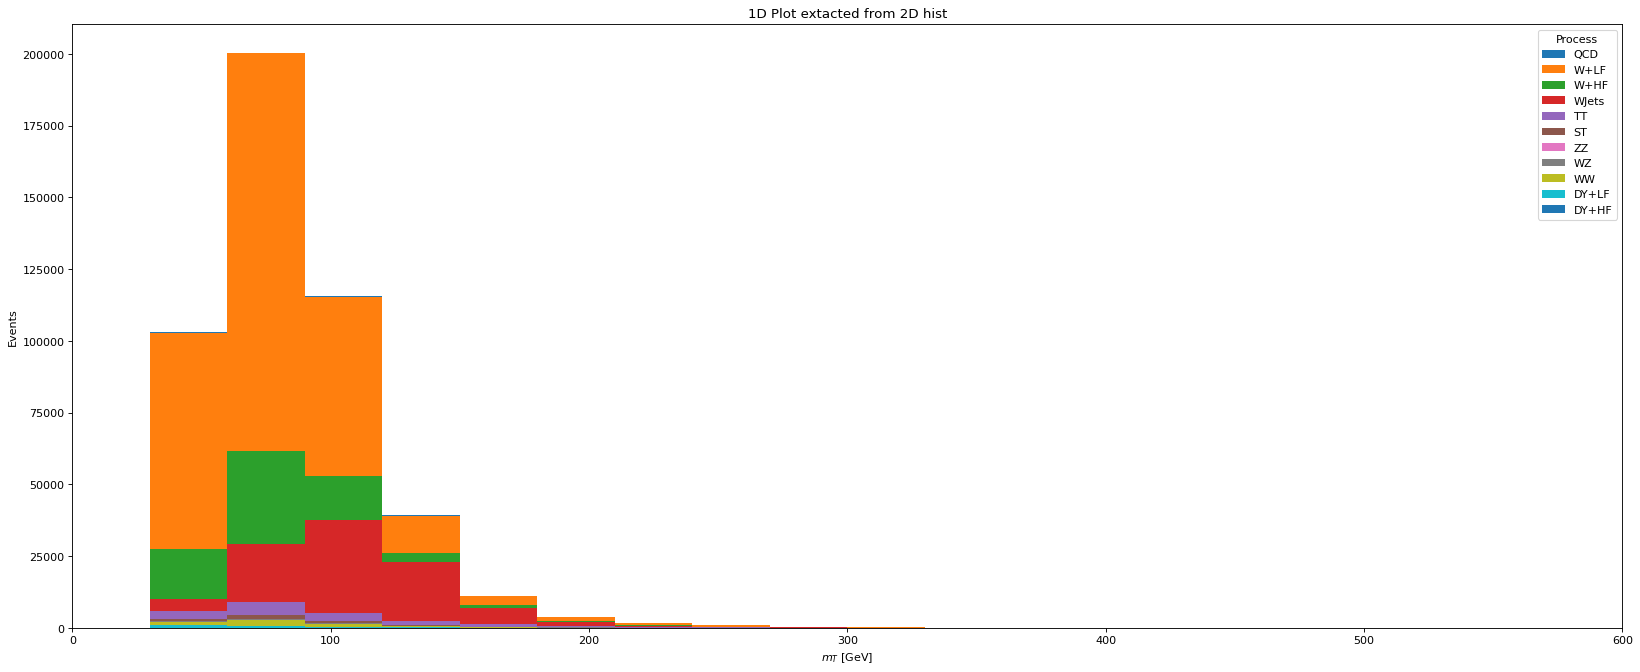

In [8]:
from matplotlib.pyplot import figure

figure(figsize=(25, 10), dpi=80)
plot.plot1d(bkg_hists['template_mt_dphi_met_lj'].integrate('region', 'wjete').integrate('systematic', 'nominal').integrate('dphi_Met_LJ')[()], stack=True)
plt.title("1D Plot extacted from 2D hist")

Text(0.5, 1.0, '1D Plot extacted from 1D hist')

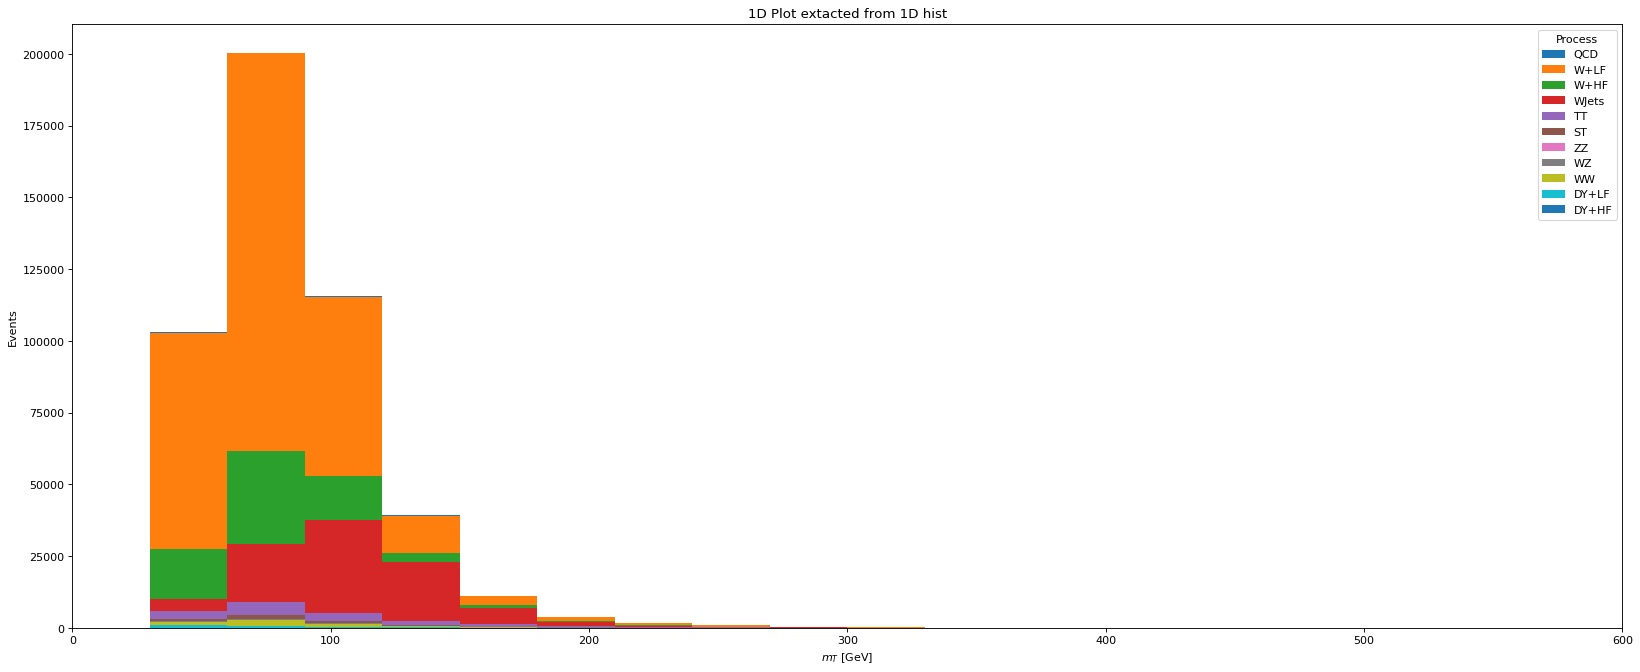

In [9]:
from matplotlib.pyplot import figure

figure(figsize=(25, 10), dpi=80)
plot.plot1d(bkg_hists['mT'].integrate('region', 'wjete'), overlay='process', stack=True)
plt.title("1D Plot extacted from 1D hist")

In [17]:
bkg_hists['sumw'].integrate('process', 'WJets').values(overflow='all')[()][1]

21566889463477.0